In [1]:
import spiceypy
import numpy as np
import datetime
import pandas as pd

In [2]:
spiceypy.furnsh('../Kernels/spk/de432s.bsp')
spiceypy.furnsh('../Kernels/lsk/naif0012.tls.txt')
spiceypy.furnsh('../Kernels/pck/pck00010.tpc')

In [3]:
init_time = datetime.datetime(year=2021, month=10, day=1)
end_time = datetime.datetime(year=2022, month=6, day=1)

init_time_str = init_time.strftime("%Y-%M-%dT%H:%M:%S")
end_time_str = end_time.strftime("%Y-%M-%dT%H:%M:%S")

init_time_et = spiceypy.utc2et(init_time_str)
end_time_et = spiceypy.utc2et(end_time_str)

print(init_time_et)
print(end_time_et)


660052869.1830854
691588869.1830791


In [4]:
delta_hours_in_seconds = 3600
time_interval_et = np.arange(init_time_et, end_time_et, delta_hours_in_seconds)

In [5]:
solar_sys_df = pd.DataFrame()

solar_sys_df.loc[:, 'ET'] = time_interval_et

solar_sys_df.loc[:, "UTC"] = solar_sys_df["ET"].apply(lambda x: spiceypy.et2datetime(et=x))




In [30]:
solar_sys_df.loc[:, "EARTH_VEN2SUN_ANGLE"] = \
    solar_sys_df["ET"].apply(lambda x: np.degrees(spiceypy.phaseq(et=x, target="399", illmn="10", obsrvr="299", abcorr="LT+S")))

solar_sys_df.loc[:, "EARTH_MOON2SUN_ANGLE"] = \
    solar_sys_df["ET"].apply(lambda x: np.degrees(spiceypy.phaseq(et=x, target="399", illmn='10', obsrvr='301', abcorr='LT+S')))

solar_sys_df.loc[:, "EARTH_MOON2VEN_ANGLE"] = \
    solar_sys_df["ET"].apply(lambda x: np.degrees(spiceypy.phaseq(et=x, target='301', illmn='299', obsrvr='399', abcorr='LT+S')))



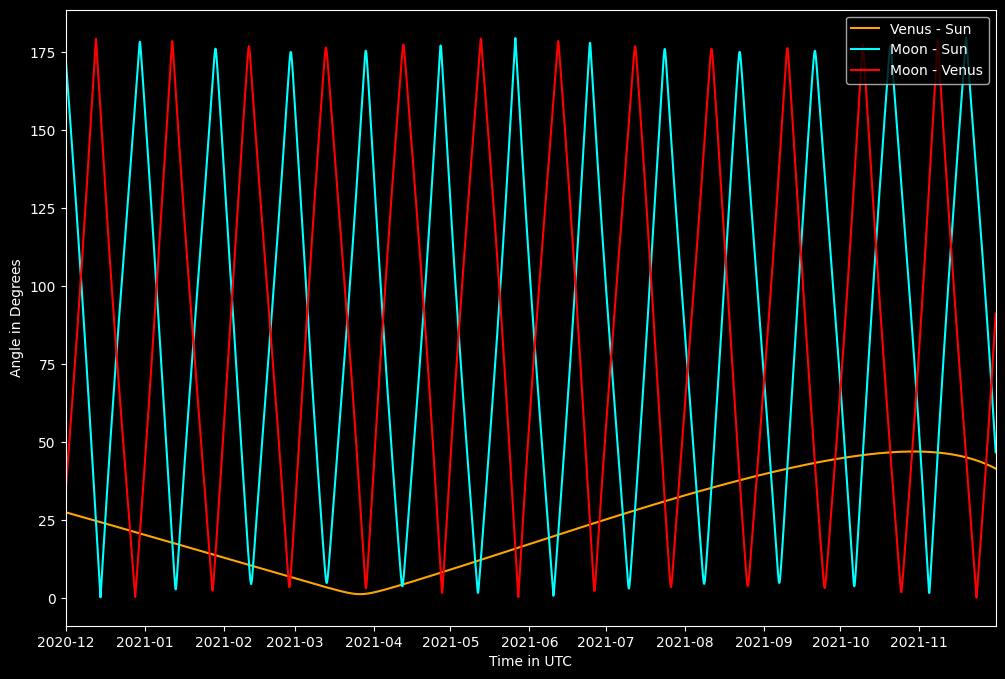

In [35]:
from matplotlib import pyplot as plt

plt.style.use("dark_background")

fig, ax = plt.subplots(figsize=(12,8))

ax.plot(solar_sys_df["UTC"], solar_sys_df["EARTH_VEN2SUN_ANGLE"], color = "Orange", label = "Venus - Sun")
ax.plot(solar_sys_df["UTC"], solar_sys_df["EARTH_MOON2SUN_ANGLE"], color = "Cyan", label = "Moon - Sun")
ax.plot(solar_sys_df["UTC"], solar_sys_df["EARTH_MOON2VEN_ANGLE"], color = "Red", label = "Moon - Venus")

ax.set_xlim(min(solar_sys_df["UTC"]), max(solar_sys_df["UTC"]))

ax.set_xlabel("Time in UTC")
ax.set_ylabel("Angle in Degrees")

ax.legend(fancybox=True, loc = "upper right")